# 04 · Case study and critical analysis

Runs the prototype pipeline for one urban location that was **not used for training** and checks the result
against an **independent** map. It then quantifies three limitations for the critical discussion:

| Section | Question |
|---|---|
| 1–3 | Prototype output: 12 monthly maps, class percentages, month-to-month and total change |
| 4 | Sanity check against the Esri 10 m Annual LULC map (Sentinel-2 based, different model, not used for training) |
| 5 | Seasonal effects: which class shares oscillate during the year without any land-use change? |
| 6 | Error inflation: how much of the calculated change is classification noise? |

The prototype app (`app/streamlit_app.py`) uses exactly the same code (`src/prototype.py`).

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import warnings
warnings.filterwarnings("ignore", message=".*restricted mode.*")   # Earth Engine quota notice

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C, gee_data as G, evaluation as E, prototype as P, plots

G.init()
print("Model:", P.MODEL_PATH)

Model: /Users/namratabhoyar/Documents/lulc-s1/weights/best_model.keras


In [2]:
CITY = "Munich, Germany"
LAT, LON = 48.137, 11.575      # city centre; not inside any training, validation or test region
START = "2025-01"              # 12 months: Jan - Dec 2025 (test period; Esri reference available for 2025)
SIZE_PX = 1024                 # 10.24 x 10.24 km

r = P.run(LAT, LON, START, size_px=SIZE_PX)
nearest = min(C.AOIS, key=lambda n: (C.AOIS[n]["lat"] - LAT) ** 2 + (C.AOIS[n]["lon"] - LON) ** 2)
print(f"{CITY}: {r['size_km']} km square, orbit {r['orbit']}, scenes per month {list(r['scenes'].values())}")
print(f"Nearest study area: {nearest} ({C.AOIS[nearest]['lat']}, {C.AOIS[nearest]['lon']})")

Munich, Germany: 10.24 km square, orbit DESCENDING, scenes per month [8, 7, 9, 10, 12, 12, 13, 12, 13, 13, 11, 14]
Nearest study area: po_valley_it (45.1, 10.0)


## 1. Monthly land-cover maps

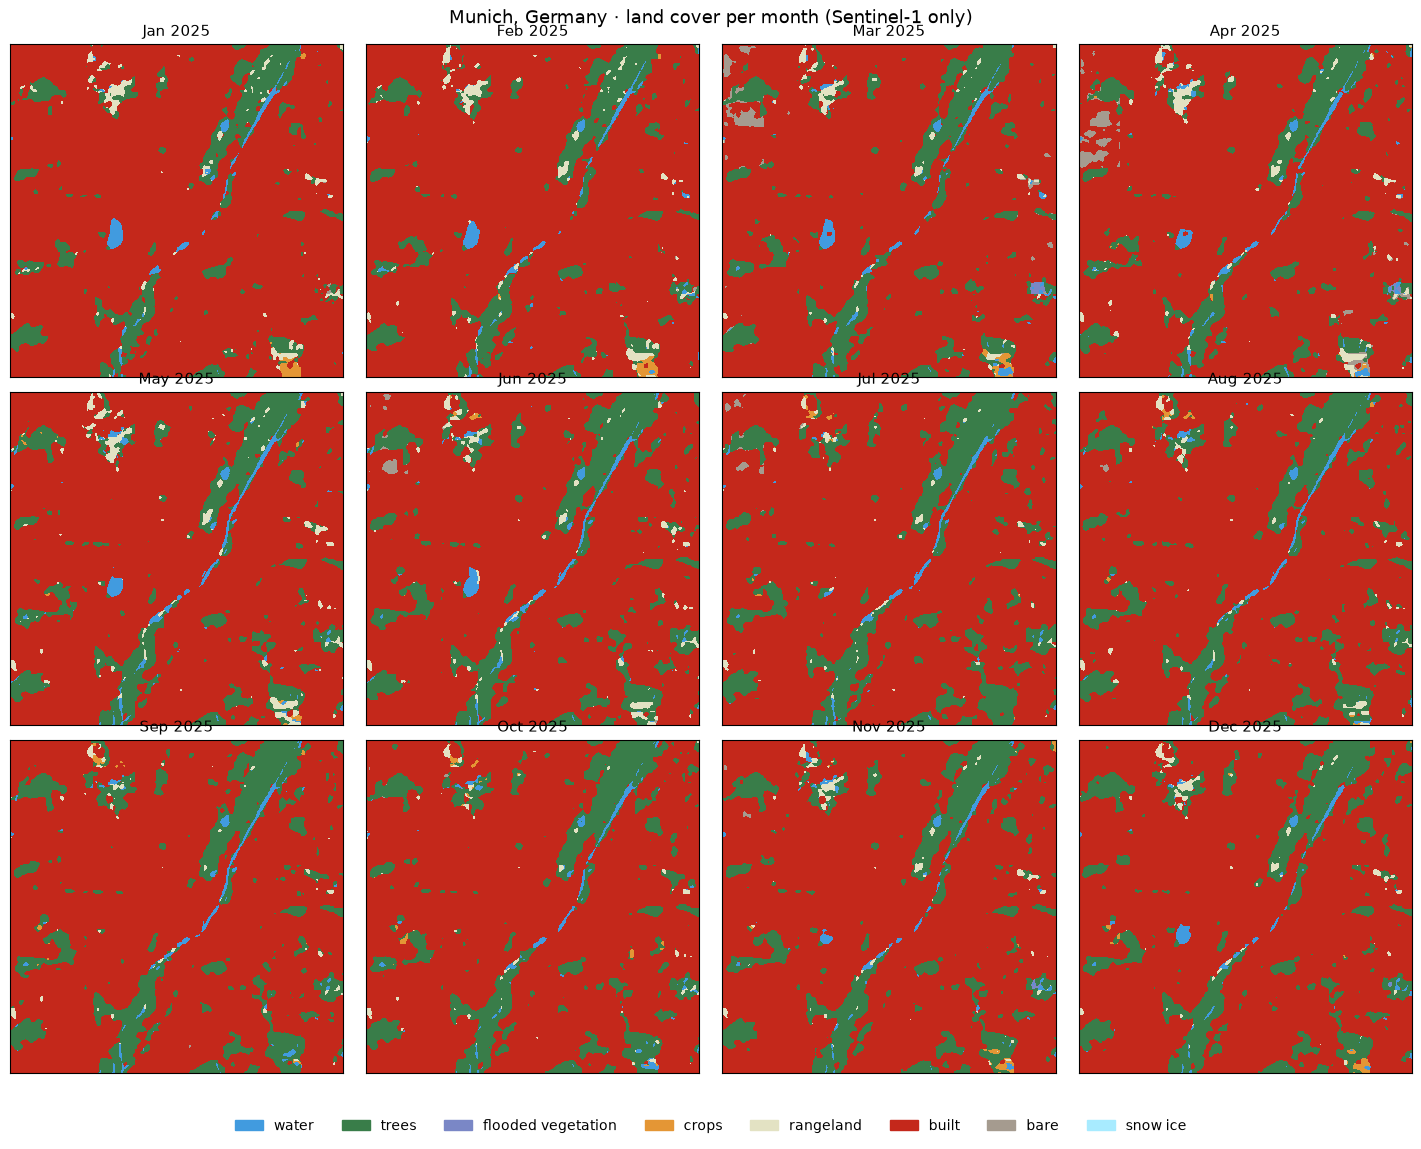

In [3]:
fig = plots.maps_grid(r["maps"], r["months"], title=f"{CITY} · land cover per month (Sentinel-1 only)")
plt.show()

## 2. Class percentages per month

Share of the mapped area: class pixels / pixels with radar data × 100.

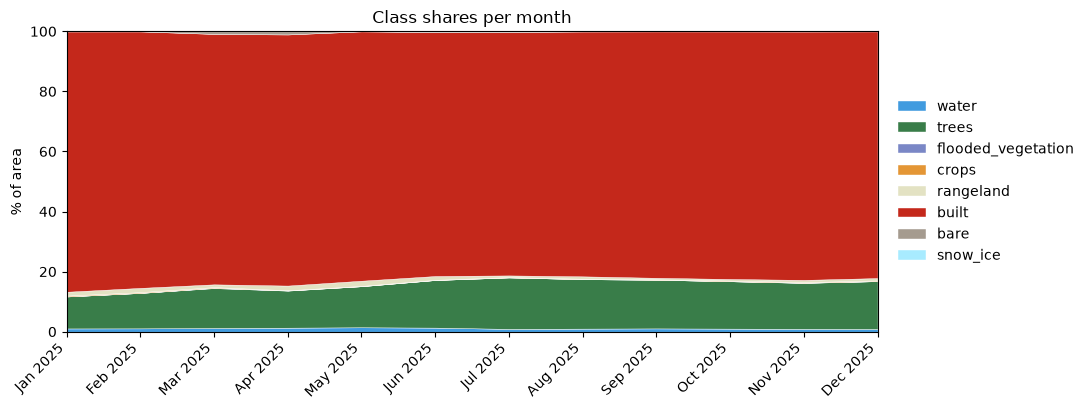

,water,trees,flooded_vegetation,crops,rangeland,built,bare,snow_ice
month,,,,,,,,
Jan 2025,1.1,10.6,0.0,0.3,1.3,86.7,0.0,0.0
Feb 2025,1.1,11.8,0.0,0.3,1.4,85.4,0.0,0.0
Mar 2025,1.2,13.3,0.1,0.2,0.9,83.4,0.9,0.0
Apr 2025,1.3,12.3,0.1,0.1,1.6,83.6,1.0,0.0
May 2025,1.5,13.7,0.0,0.1,1.7,83.0,0.0,0.0
Jun 2025,1.3,15.9,0.0,0.1,1.3,81.2,0.3,0.0
Jul 2025,0.9,17.1,0.0,0.1,0.6,81.1,0.2,0.0
Aug 2025,1.0,16.5,0.0,0.1,0.8,81.5,0.0,0.0
Sep 2025,1.1,16.2,0.0,0.1,0.5,82.1,0.0,0.0


In [4]:
plots.pct_chart(r["pct"]); plt.show()
r["pct"].rename(index=plots.month_label).round(1)

## 3. Changes in percentage points

* **Month-to-month:** share(month) − share(previous month)
* **Total:** share(last month) − share(first month)

,water,trees,flooded_vegetation,crops,rangeland,built,bare,snow_ice
month,,,,,,,,
Feb 2025,0.03,1.15,0.00,-0.02,0.13,-1.28,-0.00,0.0
Mar 2025,0.12,1.49,0.11,-0.05,-0.50,-2.02,0.84,0.0
Apr 2025,0.10,-0.94,-0.06,-0.16,0.65,0.23,0.18,0.0
May 2025,0.14,1.34,-0.06,0.04,0.17,-0.58,-1.04,0.0
Jun 2025,-0.12,2.18,0.00,-0.03,-0.47,-1.81,0.25,0.0
Jul 2025,-0.42,1.29,0.00,0.05,-0.71,-0.17,-0.04,0.0
Aug 2025,0.09,-0.67,0.00,0.02,0.24,0.49,-0.18,0.0
Sep 2025,0.08,-0.27,0.00,-0.01,-0.29,0.52,-0.03,0.0
Oct 2025,-0.08,-0.42,0.00,0.09,0.02,0.38,0.01,-0.0


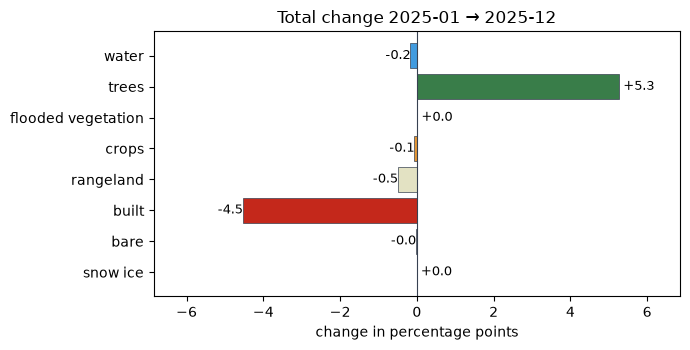

,total change (pp)
water,-0.17
trees,5.27
flooded_vegetation,0.02
crops,-0.07
rangeland,-0.50
built,-4.54
bare,-0.02
snow_ice,0.00


In [5]:
display(r["month_to_month"].iloc[1:].rename(index=plots.month_label).round(2))
plots.total_change_chart(r["total"]); plt.show()
r["total"].round(2).to_frame("total change (pp)")

## 4. Sanity check against an independent map

The **Esri 10 m Annual LULC** map is derived from Sentinel-2 by a different model (Impact Observatory) and was
**not used for training** (training labels came from Dynamic World). It has the same eight classes. Because it is
annual, it is compared with the most frequent class per pixel over the 12 months.

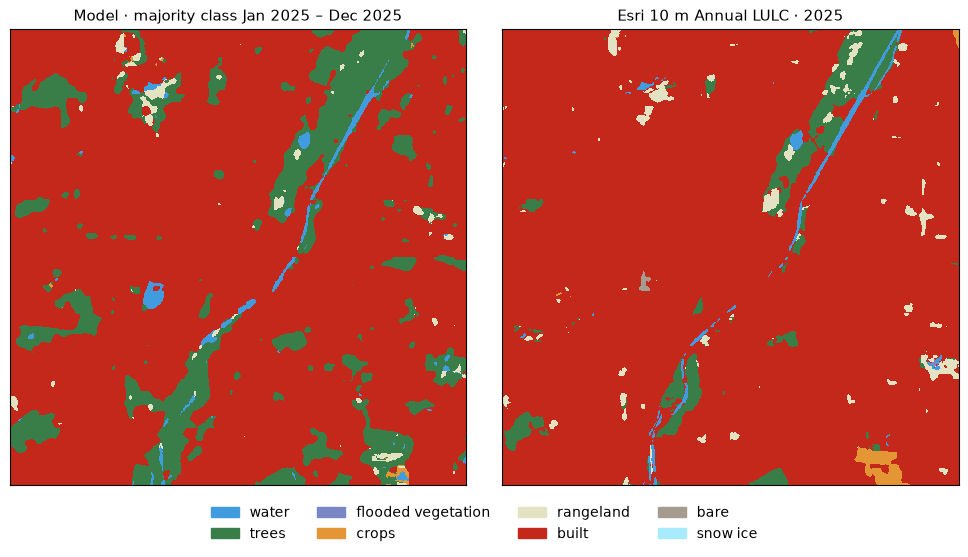

Esri year: 2025 | pixel agreement: 87.9 %


,model_%,reference_%,difference_pp
water,1.1,0.9,0.2
trees,14.9,4.6,10.3
flooded_vegetation,0.0,0.0,-0.0
crops,0.1,0.6,-0.5
rangeland,0.9,1.8,-0.8
built,82.9,92.1,-9.2
bare,0.0,0.1,-0.1
snow_ice,0.0,0.0,0.0


In [6]:
pred_annual = P.annual_majority(r["maps"], r["months"])
plots.reference_pair(pred_annual, r["ref_map"], r["ref_year"], r["months"]); plt.show()
print(f"Esri year: {r['ref_year']} | pixel agreement: {100 * r['ref_agreement']:.1f} %")
r["ref_table"].round(1)

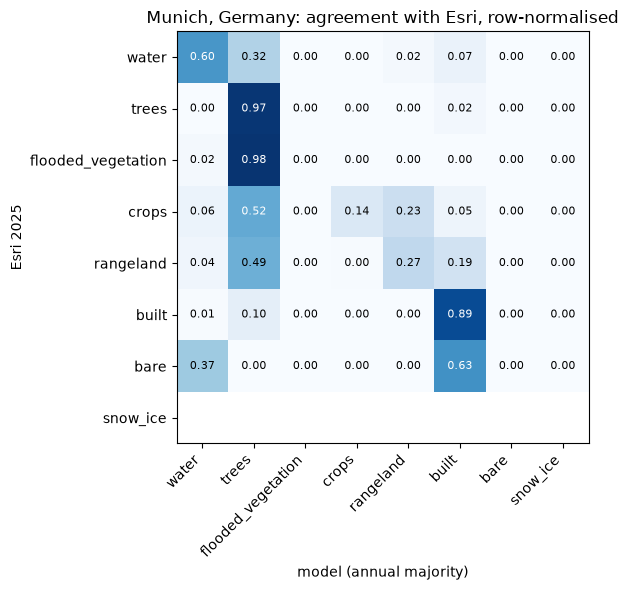

,IoU,precision,recall,F1,support_%
water,0.362,0.476,0.602,0.532,0.907
trees,0.299,0.302,0.973,0.461,4.628
flooded_vegetation,0.000,0.000,0.000,0.000,0.017
crops,0.135,0.733,0.142,0.238,0.560
rangeland,0.213,0.510,0.267,0.351,1.752
built,0.889,0.993,0.894,0.941,92.072
bare,0.000,0.000,0.000,0.000,0.064
snow_ice,NaN,NaN,NaN,NaN,0.000


In [7]:
cm = E.confusion(r["ref_map"], pred_annual)       # rows: Esri, columns: model
with np.errstate(invalid="ignore"):
    cm_norm = cm / cm.sum(1, keepdims=True)
present = cm.sum(1) > 0
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.imshow(np.where(present[:, None], cm_norm, np.nan), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(C.CLASSES)), C.CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(C.CLASSES)), C.CLASSES)
for i in np.where(present)[0]:
    for j in range(len(C.CLASSES)):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xlabel("model (annual majority)"); ax.set_ylabel(f"Esri {r['ref_year']}")
ax.set_title(f"{CITY}: agreement with Esri, row-normalised")
plt.tight_layout(); plt.show()
E.scores(cm)["per_class"].round(3)

## 5. Seasonal effects

Within one year, the true land use of a city changes by at most a few tenths of a percent. Larger swings in a
class share are therefore mostly **seasonal backscatter changes** (vegetation growth and harvest, soil moisture,
snow, flooding) that the model turns into class changes.

,mean_%,min_%,max_%,range_pp,std_pp,month_of_max
trees,14.54,10.65,17.14,6.50,2.11,Jul 2025
built,82.95,81.06,86.69,5.64,1.68,Jan 2025
rangeland,1.00,0.51,1.73,1.22,0.42,May 2025
bare,0.21,0.00,1.04,1.04,0.36,Apr 2025
water,1.12,0.90,1.46,0.56,0.18,May 2025
crops,0.17,0.06,0.29,0.23,0.08,Jan 2025
flooded_vegetation,0.02,0.00,0.11,0.11,0.04,Mar 2025
snow_ice,0.00,0.00,0.00,0.00,0.00,Sep 2025


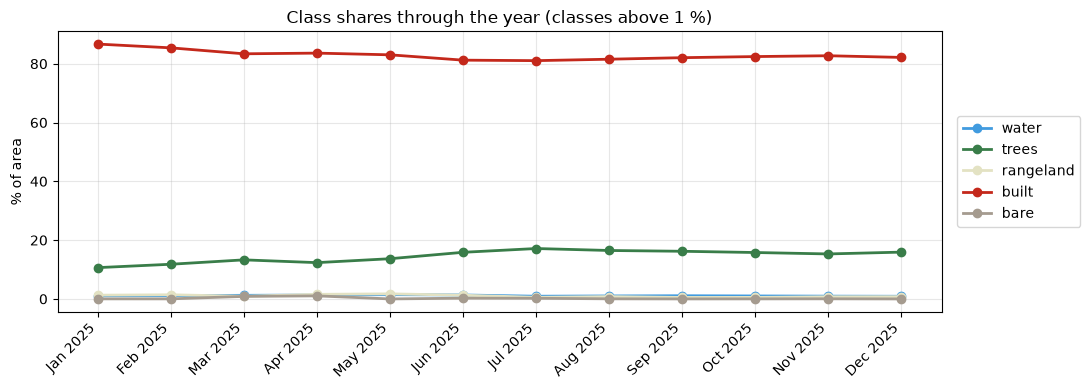

In [8]:
seasonal = pd.DataFrame({"mean_%": r["pct"].mean(), "min_%": r["pct"].min(), "max_%": r["pct"].max(),
                         "range_pp": r["pct"].max() - r["pct"].min(), "std_pp": r["pct"].std()})
seasonal["month_of_max"] = r["pct"].idxmax().map(lambda m: plots.month_label(m) if isinstance(m, str) else m)
display(seasonal.sort_values("range_pp", ascending=False).round(2))

fig, ax = plt.subplots(figsize=(11, 4))
for c, color in zip(C.CLASSES, C.CLASS_COLORS):
    if r["pct"][c].max() > 1:
        ax.plot(range(12), r["pct"][c], marker="o", color=color, label=c, lw=2)
ax.set_xticks(range(12), [plots.month_label(m) for m in r["months"]], rotation=45, ha="right")
ax.set_ylabel("% of area"); ax.grid(alpha=0.3); ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.set_title("Class shares through the year (classes above 1 %)")
plt.tight_layout(); plt.show()

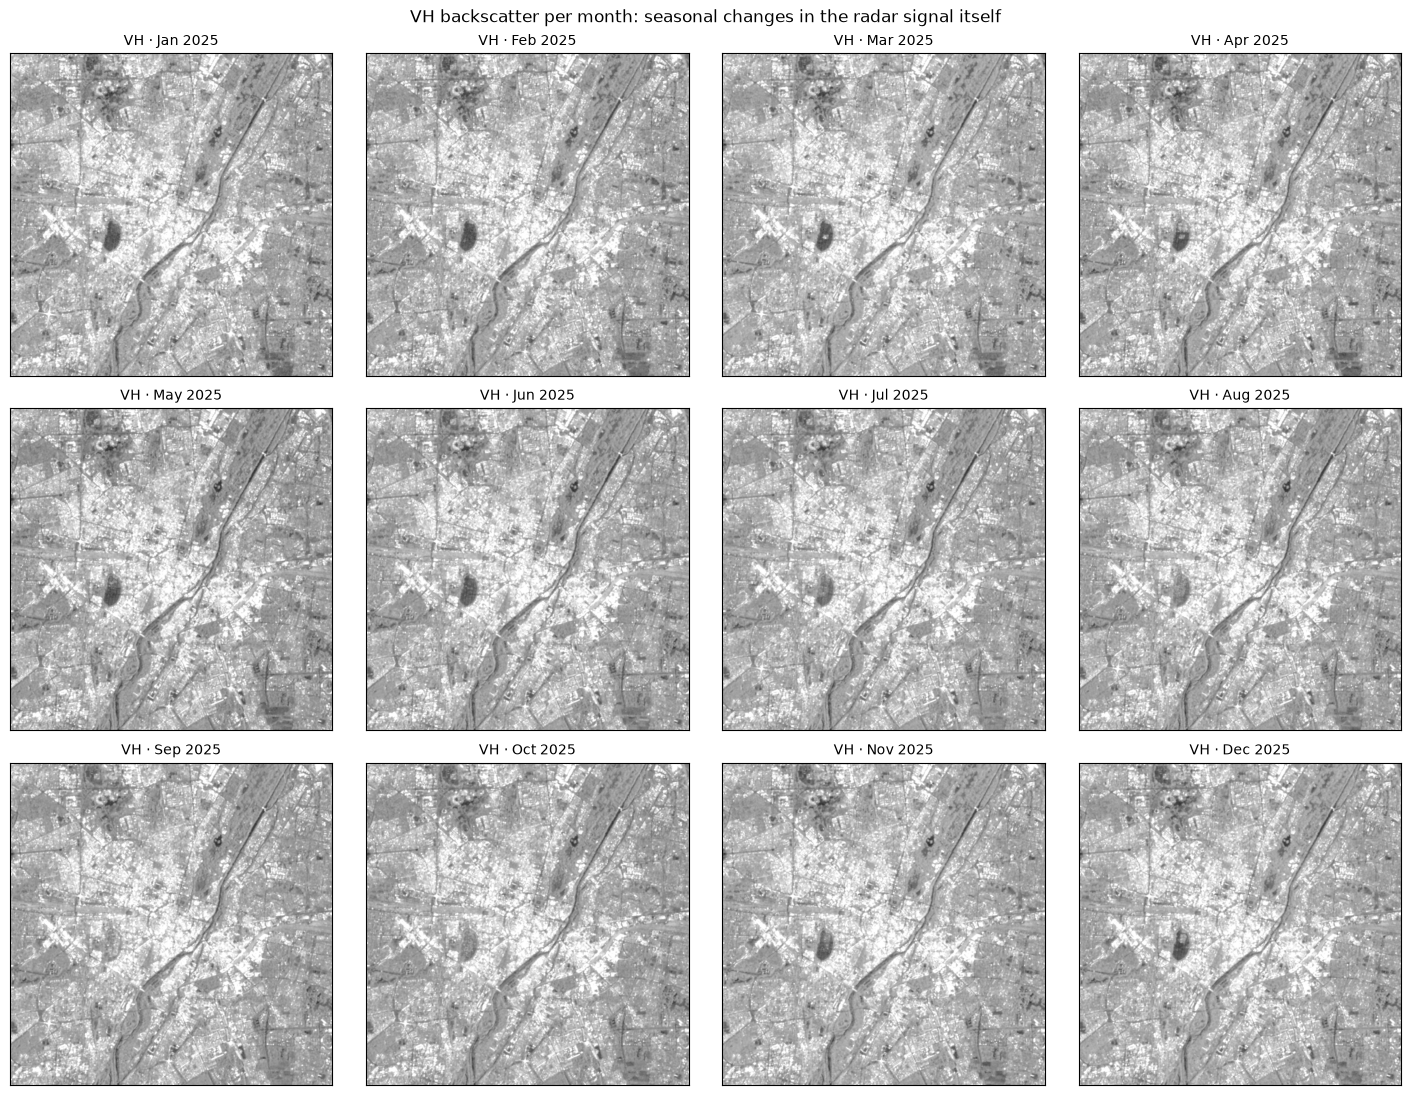

,VV,VH,VV_VH
Jan 2025,-5.36,-12.92,7.56
Feb 2025,-5.47,-12.99,7.51
Mar 2025,-5.17,-12.62,7.45
Apr 2025,-5.60,-12.94,7.34
May 2025,-5.63,-13.46,7.83
Jun 2025,-5.41,-13.06,7.65
Jul 2025,-5.15,-12.98,7.83
Aug 2025,-5.31,-13.00,7.69
Sep 2025,-5.24,-13.13,7.89
Oct 2025,-5.34,-13.16,7.81


In [9]:
fig = plots.s1_grid(r["s1"], r["months"], band=1)
fig.suptitle("VH backscatter per month: seasonal changes in the radar signal itself", y=1.01)
plt.show()
monthly_db = pd.DataFrame({m: np.nanmean(a, (0, 1)) for m, a in r["s1"].items() if a is not None},
                          index=C.S1_BANDS).T.rename(index=plots.month_label)
monthly_db.round(2)

## 6. How classification errors inflate change

**Gross vs. net change.** The net change of a class share hides how many pixels actually switched class: pixels
switching *into* and *out of* a class cancel out. The share of pixels whose class differs from the previous month
(gross change) is an upper bound for real change plus noise.

In [10]:
def gross_change(maps, months):
    rows = {}
    for prev, cur in zip(months[:-1], months[1:]):
        a, b = maps[prev], maps[cur]
        if a is None or b is None:
            continue
        keep = (a != C.IGNORE) & (b != C.IGNORE)
        rows[plots.month_label(cur)] = 100 * (a[keep] != b[keep]).mean()
    return pd.Series(rows, name="pixels changing class (%)")

smoothed = P.temporal_mode(r["maps"], r["months"])
pct_s = P.class_percentages(smoothed, r["months"])
mtm_s, total_s = P.changes(pct_s)

gross = pd.DataFrame({"raw": gross_change(r["maps"], r["months"]),
                      "3-month majority": gross_change(smoothed, r["months"])})
display(gross.round(1))
print(f"Mean share of pixels changing class per month: raw {gross['raw'].mean():.1f} %, "
      f"smoothed {gross['3-month majority'].mean():.1f} %")

,raw,3-month majority
Feb 2025,4.3,1.5
Mar 2025,5.2,2.3
Apr 2025,5.9,2.2
May 2025,5.6,2.2
Jun 2025,4.4,2.4
Jul 2025,4.5,1.7
Aug 2025,4.3,1.8
Sep 2025,3.4,1.3
Oct 2025,3.8,1.7
Nov 2025,4.6,2.2


Mean share of pixels changing class per month: raw 4.5 %, smoothed 1.9 %


In [11]:
compare = pd.DataFrame({
    "mean |month-to-month| raw (pp)": r["month_to_month"].abs().mean(),
    "mean |month-to-month| smoothed (pp)": mtm_s.abs().mean(),
    "total raw (pp)": r["total"],
    "total smoothed (pp)": total_s,
})
compare.round(2)

,mean |month-to-month| raw (pp),mean |month-to-month| smoothed (pp),total raw (pp),total smoothed (pp)
water,0.12,0.11,-0.17,-0.20
trees,0.99,0.71,5.27,4.07
flooded_vegetation,0.03,0.01,0.02,0.02
crops,0.05,0.04,-0.07,-0.13
rangeland,0.31,0.16,-0.50,-0.63
built,0.76,0.71,-4.54,-3.13
bare,0.24,0.06,-0.02,-0.00
snow_ice,0.00,0.00,0.00,0.00


**Expected spurious change if errors were random.** If a pixel were classified correctly with probability *p*
each month and the errors in different months were independent, a pixel whose land cover does not change would
still appear to change between two months with probability ≈ 1 − p². This is an upper bound: comparing it with
the observed share shows whether the errors are mostly random (they would inflate change) or mostly systematic
(the same mistake every month: it biases the class shares but largely cancels in the change).

In [12]:
results = json.loads((ROOT / "weights" / "results.json").read_text()) if (ROOT / "weights" / "results.json").exists() else None
p_test = results["test"][results["selected_model"]]["OA"] if results else None
for label, p in [("test-set OA", p_test), ("agreement with Esri here", r["ref_agreement"])]:
    if p is not None:
        print(f"p = {p:.3f} ({label}): expected share of pixels with spurious change between two months "
              f"≈ {100 * (1 - p ** 2):.1f} %")
print(f"Observed share of pixels changing class per month: {gross['raw'].mean():.1f} %")

p = 0.510 (test-set OA): expected share of pixels with spurious change between two months ≈ 73.9 %
p = 0.879 (agreement with Esri here): expected share of pixels with spurious change between two months ≈ 22.7 %
Observed share of pixels changing class per month: 4.5 %


### Summary for the critical discussion

* **Agreement with the independent map:** 87.9 % of pixels agree with the Esri 2025 map; built-up, which covers
  92 % of the area, reaches F1 0.94. The largest difference is trees (model 14.9 %, Esri 4.6 %). Much of it is a
  difference in class definitions rather than a model error: Esri counts trees inside the city (parks, tree-lined
  streets) as built area, whereas Dynamic World, the source of the training labels, maps them as trees.
* **Seasonal effects:** the tree share rises from 10.6 % in January to 17.1 % in July while built-up falls from
  86.7 % to 81.1 %. Leafless deciduous trees in winter give little volume scattering (low VH) and are classified as
  built-up; with leaves they become trees again. The scene-average backscatter changes by less than 0.7 dB, enough
  to flip pixels near the class boundary. Sentinel-1C adds scenes from spring 2025 (8 scenes in January, 14 in
  December), which also changes the composites without any change on the ground.
* **Apparent vs. real change:** the total change January → December is +5.3 pp trees and −4.5 pp built-up, i.e.
  about 4.7 km² less built-up area within a year. Real land-use change in central Munich is far smaller, so this
  figure is dominated by seasonal and acquisition effects. A comparison of the same month in consecutive years
  would avoid the seasonal part.
* **Effect of temporal smoothing:** a 3-month majority filter lowers the share of pixels changing class each month
  from 4.5 % to 1.9 %, but the total change only from +5.3 to +4.1 pp (trees) and −4.5 to −3.1 pp (built-up):
  smoothing removes random flicker, not systematic seasonal shifts.
* **Random vs. systematic errors:** independent errors would make 23–74 % of pixels appear to change each month
  (1 − p² with p = agreement with Esri or test OA); only 4.5 % do. Most errors are therefore systematic: they bias
  the class shares (trees +10 pp against Esri) but largely cancel in month-to-month changes. The change error comes
  from the part of the signal that varies with season and acquisitions.